# 02 · Outlier Detection and Treatment

Objective: detect extreme values in `adr`, `lead_time` and total length
of stay, assess whether they are plausible or errors, and decide what to
keep, correct or exclude, checking their effect on the cancellation rate.

Data: this notebook uses the cleaned CSV produced by `01_cleaning` (`hotels_clean.csv`:
exact duplicates, impossible values and bookings with no guests or 0 nights removed).
The analysis was first run on the original CSV (`hotels.csv`); cases that were only
visible there are noted where relevant. To switch files, change `csv_path` and re-run
the notebook (run `01_cleaning` first to create `hotels_clean.csv`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
csv_path = "../data/hotels_clean.csv"
df = pd.read_csv(csv_path)

In [3]:
df.shape

(86622, 32)

In [4]:
df.dtypes.to_frame("dtype")

,dtype
hotel,str
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,str
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,86622.0,0.276743,0.447391,0.0,0.0,0.0,1.00,1.0
lead_time,86622.0,80.254497,86.022116,0.0,12.0,50.0,125.00,709.0
arrival_date_year,86622.0,2016.212440,0.685858,2015.0,2016.0,2016.0,2017.00,2017.0
arrival_date_week_number,86622.0,26.820669,13.652455,1.0,16.0,27.0,37.00,53.0
arrival_date_day_of_month,86622.0,15.818545,8.835970,1.0,8.0,16.0,23.00,31.0
stays_in_weekend_nights,86622.0,1.011302,1.027473,0.0,0.0,1.0,2.00,19.0
stays_in_week_nights,86622.0,2.641534,2.035049,0.0,1.0,2.0,4.00,50.0
adults,86622.0,1.876417,0.504674,0.0,2.0,2.0,2.00,6.0
children,86622.0,0.139214,0.455704,0.0,0.0,0.0,0.00,3.0
babies,86622.0,0.010644,0.104293,0.0,0.0,0.0,0.00,2.0


## Variable selection

*Figures from the cleaned CSV.*

Not every numeric column can have outliers in a meaningful sense. A variable is analysed
with the IQR rule only if (1) it measures a quantity, so "much larger than the rest" makes
sense, and (2) it has enough distinct values and spread, so that Q3 − Q1 > 0.

| Variable | Analyse? | Reason |
|---|---|---|
| `lead_time` | **Yes** | Quantity (days), many distinct values, max (709) far above Q3 (125) |
| `adr` | **Yes** | Quantity (price), max 5,400 vs Q3 134 |
| `stays_in_weekend_nights` | **Yes, combined** | Summed into `total_nights` (total length of stay) |
| `stays_in_week_nights` | **Yes, combined** | Summed into `total_nights` (total length of stay) |
| `is_canceled` | No | Binary target (0/1), not a quantity |
| `is_repeated_guest` | No | Binary (0/1) |
| `arrival_date_year` | No | Date component, not a quantity |
| `arrival_date_week_number` | No | Date component (week 53 is valid in ISO years such as 2015) |
| `arrival_date_day_of_month` | No | Date component |
| `agent` | No | Identifier code; agent 535 is not "more" than agent 9 |
| `company` | No | Identifier code |
| `adults` | No | Q1 = Q3 = 2 → IQR = 0; extreme values (e.g. 55 in the original CSV) removed in data cleaning |
| `children` | No | Q1 = Q3 = 0 → IQR = 0; extreme values removed in data cleaning |
| `babies` | No | Q1 = Q3 = 0 → IQR = 0; extreme values removed in data cleaning |
| `previous_cancellations` | No | Q1 = Q3 = 0 → IQR = 0; high values are possible (e.g. agencies) |
| `previous_bookings_not_canceled` | No | Q1 = Q3 = 0 → IQR = 0 |
| `booking_changes` | No | Q1 = Q3 = 0 → IQR = 0 |
| `days_in_waiting_list` | No | Q1 = Q3 = 0 → IQR = 0; long waits are rare but possible |
| `required_car_parking_spaces` | No | Q1 = Q3 = 0 → IQR = 0 |
| `total_of_special_requests` | No | Small bounded range (0–5); no extreme values |

**Variables analysed:** `adr`, `lead_time` and `total_nights`
(= `stays_in_weekend_nights` + `stays_in_week_nights`).

In [6]:
# I will need only these columns for the outlier detection and treatment
required_columns = [
    "hotel",
    "is_canceled",
    "market_segment",
    "adr",
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
]

In [7]:
missing = []
for column in required_columns:
    if column not in df.columns:
        missing.append(column)
        
if len(missing) > 0:
    raise ValueError(f"Missing columns: {missing}")

In [8]:
#Check if the numerical variables are entirely numerical
numerical_columns = [
    'adr',
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
]

In [9]:
numerical_error = []
for column in numerical_columns:
    if not pd.api.types.is_numeric_dtype(df[column]):
        numerical_error.append(column)
        
if len(numerical_error) > 0:
    raise ValueError(f"Wrong numerical columns: {numerical_error}")

In [10]:
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

In [11]:
df[['total_nights', 'stays_in_weekend_nights', 'stays_in_week_nights']] 

,total_nights,stays_in_weekend_nights,stays_in_week_nights
0,1,0,1
1,1,0,1
2,2,0,2
3,2,0,2
4,2,0,2
...,...,...,...
86617,7,2,5
86618,7,2,5
86619,7,2,5
86620,7,2,5


In [12]:
df[['total_nights', 'stays_in_weekend_nights', 'stays_in_week_nights']].describe().T

,count,mean,std,min,25%,50%,75%,max
total_nights,86622.0,3.652836,2.735565,1.0,2.0,3.0,5.0,69.0
stays_in_weekend_nights,86622.0,1.011302,1.027473,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,86622.0,2.641534,2.035049,0.0,1.0,2.0,4.0,50.0


In [13]:
df[['adr', 'lead_time', 'total_nights']].isna().sum()

adr             0
lead_time       0
total_nights    0
dtype: int64

In [14]:
df[['adr', 'lead_time', 'total_nights']].count()

adr             86622
lead_time       86622
total_nights    86622
dtype: int64

With the cleaned CSV there are no missing values in `adr`, `lead_time` or `total_nights`,
so all 86,622 rows are used to compute quantiles.

## Outlier detection

Outlier limits are computed **separately for each hotel**. The City Hotel and the Resort Hotel
serve different customers, so a value that is normal in one can be extreme in the other
(e.g. a 10-night stay is common in a resort but rare in a city hotel). A single limit computed
on both hotels together would fit neither: it would flag normal resort bookings and could miss
unusual city bookings. The statistics below check whether the distributions really differ.

In [15]:
df.groupby('hotel')[['adr', 'lead_time', 'total_nights']].describe(percentiles = [0.01, 0.25, 0.5, 0.75, 0.99, 0.999]).T

hotel                 City Hotel  Resort Hotel
adr          count  53041.000000  33581.000000
             mean     111.757384    100.161942
             std       47.337634     63.238605
             min        0.000000      0.000000
             1%         0.000000      4.000000
             25%       85.000000     52.400000
             50%      105.740000     80.000000
             75%      134.100000    135.000000
             99%      235.402000    286.832000
             99.9%    297.240000    358.855000
             max     5400.000000    508.000000
lead_time    count  53041.000000  33581.000000
             mean      78.044286     83.745511
             std       82.136661     91.717675
             min        0.000000      0.000000
             1%         0.000000      0.000000
             25%       14.000000      8.000000
             50%       51.000000     47.000000
             75%      118.000000    139.000000
             99%      343.000000    351.000000
             99.9%    503.960000    460.840000
             max      629.000000    709.000000
total_nights count  53041.000000  33581.000000
             mean       3.155653      4.438135
             std        2.035919      3.427731
             min        1.000000      1.000000
             1%         1.000000      1.000000
             25%        2.000000      2.000000
             50%        3.000000      4.000000
             75%        4.000000      7.000000
             99%       10.000000     14.000000
             99.9%     21.000000     28.000000
             max       48.000000     69.000000

**Observations (cleaned CSV):**

- **`total_nights`**: stays are longer in the Resort Hotel (Q3 = 7, P99 = 14) than in the City Hotel
  (Q3 = 4, P99 = 10). A 10-night stay is rare in the city but normal in the resort, which confirms
  computing limits per hotel.
- **`adr`**: the City Hotel maximum (5,400) is about 18 times its 99.9th percentile (≈ 297),
  an isolated value to review.
- **`adr`**: at least 1% of City Hotel bookings have a rate of 0; they are reviewed in section 4.
  The negative rate seen in the original CSV (−6.38, Resort Hotel) was removed in `01_cleaning`.

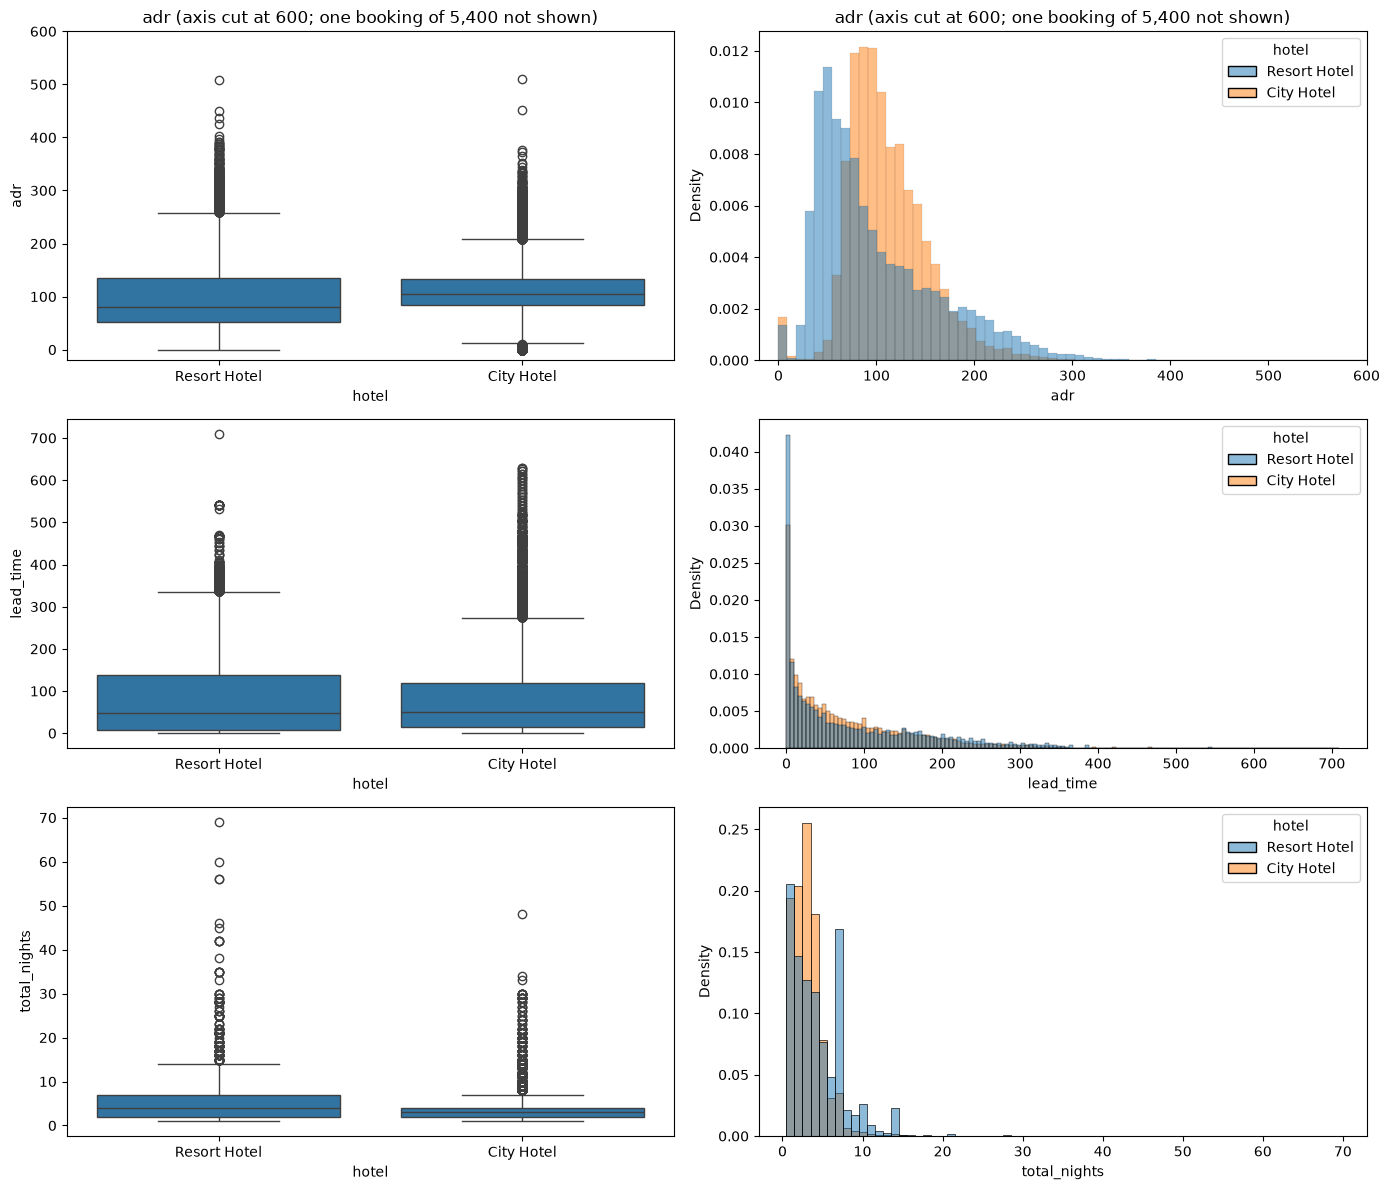

In [16]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for i, var in enumerate(["adr", "lead_time", "total_nights"]):
    # Left column: boxplot per hotel
    sns.boxplot(data=df, x="hotel", y=var, ax=axes[i, 0])

    sns.histplot(
        data=df, x=var, hue="hotel",
        stat="density", common_norm=False,
        discrete=(var == "total_nights"),
        ax=axes[i, 1],
    )

axes[0, 0].set_ylim(-20, 600)
axes[0, 1].set_xlim(-20, 600)
axes[0, 0].set_title("adr (axis cut at 600; one booking of 5,400 not shown)")
axes[0, 1].set_title("adr (axis cut at 600; one booking of 5,400 not shown)")

plt.tight_layout()
plt.show()

**What the plots show (cleaned CSV):**

- **`adr`**: right-skewed in both hotels. City Hotel prices are more concentrated
  (Q1 = 85, Q3 = 134), while Resort Hotel prices are more spread out (Q1 = 52, Q3 = 135,
  P99 = 287), probably due to seasonality. Apart from the single value of 5,400,
  no rate goes above 510.
- **`lead_time`**: strongly right-skewed. The Resort Hotel has slightly more last-minute bookings
  (Q1 = 8 vs 14 days), and both hotels have a long tail of bookings made more than a year in advance.
  The points above the whiskers form a continuous tail, not isolated cases.
- **`total_nights`**: City Hotel stays are mostly 1–4 nights (83% of its bookings). The Resort Hotel
  shows peaks at 7 nights (16.9% of its bookings vs 3.5% in the City Hotel) and 14 nights
  (2.3% vs 0.2%), which suggests one- and two-week holiday stays.

The distributions differ clearly between hotels, which supports computing IQR limits per hotel.
Because the variables are right-skewed, the 1.5 × IQR rule is expected to flag many
values in the upper tail; these are candidates to review, not errors.

In [17]:
variables = ["adr", "lead_time", "total_nights"]
results = []   

for var in variables:
    q1 = df.groupby("hotel")[var].quantile(0.25)
    q3 =  df.groupby("hotel")[var].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - (1.5*iqr)
    upper = q3 + (1.5*iqr)

    
    flag_col = f"flag_{var}"
    df[flag_col] = (df[var] > df["hotel"].map(upper)) | ((df[var] < df["hotel"].map(lower)))

    
    table = pd.DataFrame({
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower": lower,
        "upper": upper,
        "n_values": df.groupby("hotel")[var].count(),
        "n_flagged":  df.groupby("hotel")[flag_col].sum(),
        "pct_flagged":  df.groupby("hotel")[flag_col].mean()*100,
    })
    table["variable"] = var
    results.append(table)

iqr_table = pd.concat(results)
iqr_table.round(2)

,Q1,Q3,IQR,lower,upper,n_values,n_flagged,pct_flagged,variable
hotel,,,,,,,,,
City Hotel,85.0,134.1,49.1,11.35,207.75,53041,2219,4.18,adr
Resort Hotel,52.4,135.0,82.6,-71.50,258.90,33581,735,2.19,adr
City Hotel,14.0,118.0,104.0,-142.00,274.00,53041,1694,3.19,lead_time
Resort Hotel,8.0,139.0,131.0,-188.50,335.50,33581,562,1.67,lead_time
City Hotel,2.0,4.0,2.0,-1.00,7.00,53041,1157,2.18,total_nights
Resort Hotel,2.0,7.0,5.0,-5.50,14.50,33581,217,0.65,total_nights


In [18]:
df['any_flag'] = df[['flag_adr', 'flag_lead_time', 'flag_total_nights']].any(axis=1)

In [19]:
df['any_flag'].sum()


np.int64(6442)

In [20]:
df['any_flag'].mean()

np.float64(0.07436909791969708)

In [21]:
df[['flag_adr', 'flag_lead_time', 'flag_total_nights', 'any_flag']]

,flag_adr,flag_lead_time,flag_total_nights,any_flag
0,False,False,False,False
1,False,False,False,False
2,False,False,False,False
3,False,False,False,False
4,False,False,False,False
...,...,...,...,...
86617,False,False,False,False
86618,True,False,False,True
86619,False,False,False,False
86620,False,False,False,False


**IQR results (cleaned CSV):**

- **`adr`**: 2,219 candidates in the City Hotel (4.2%) and 735 in the Resort Hotel (2.2%).
  In the City Hotel the lower limit is positive (11.35), so 816 bookings with very low rates
  (including rates of 0) are flagged below; in the Resort Hotel the lower limit is negative (−71.5),
  so no booking is flagged below. In the original CSV, the negative rate (−6.38) was **not** flagged,
  because it lay above the Resort Hotel lower limit: the IQR rule finds values far from the rest,
  not impossible values. That booking was removed in `01_cleaning`.
- **`lead_time`**: the upper limit is 274 days in the City Hotel and 335.5 in the Resort Hotel;
  the City Hotel has about twice the share of candidates (3.2% vs 1.7%). Lower limits are negative,
  so only very long lead times are flagged.
- **`total_nights`**: limits per hotel work as expected: the upper limit is 7 nights in the
  City Hotel and 14.5 in the Resort Hotel, so a two-week holiday is normal in the resort but
  flagged in the city (1,157 candidates in the City Hotel, 2.2%; 217 in the Resort Hotel, 0.6%).

**Total:** 6,442 bookings (7.44%) are flagged in at least one variable. This is 142 fewer
than the sum of the flags per variable (6,584), because some bookings are flagged in more
than one variable. These are **candidates to review**, not errors to remove.

In [22]:
context_columns = [
    "hotel",
    "adr",
    "lead_time",
    "total_nights",
    "market_segment",
    "customer_type",
    "adults",
]

In [23]:
df[df["adr"] >= 1000]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_nights,flag_adr,flag_lead_time,flag_total_nights,any_flag
38331,City Hotel,1,35,2016,March,13,25,0,1,2,...,5400.0,0,0,Canceled,2016-02-19,1,True,False,False,True


In [24]:
df['exclude'] = df["adr"] >= 1000

In [25]:
df['exclude'].sum()

np.int64(1)

In [26]:
same_month_city = df[
    (df["hotel"] == "City Hotel")
    & (df["arrival_date_year"] == 2016)
    & (df["arrival_date_month"] == "March")
]
same_month_city["adr"].median()

np.float64(85.85)

**Rate of 5,400 (City Hotel)**

One booking in the City Hotel has `adr` = 5,400: 1 night, 2 adults, standard room type A,
transient customer, *Offline TA/TO* segment. The City Hotel median rate that month
(March 2016) is ≈ 86, and the next highest rate in the whole dataset is 510.
Nothing in the booking explains such a price, so it is an **inconsistency**, most likely
a data entry error. It is still present after `01_cleaning`, which only removes negative rates.

**Decision: exclude.** The true value cannot be recovered, so it cannot be corrected.
Removing one booking out of 86,622 has no impact on the analysis.
The booking is marked in the `exclude` column, and the exclusion is applied in section 5.

In [27]:
df.loc[df["adr"] <0, context_columns]

,hotel,adr,lead_time,total_nights,market_segment,customer_type,adults


**Negative rate**

In the original CSV, one booking in the Resort Hotel had `adr` = −6.38 (10 nights, *Groups* segment).
A negative daily rate is impossible, but the IQR rule did **not** flag it, because it lay
above the Resort Hotel lower limit. This shows that the IQR rule finds values far
from the rest, not invalid values.

**Decision:** treated in `01_cleaning`, where it is removed. With the cleaned CSV the cell above
returns no rows.

In [28]:
# Lower adr limit of the City Hotel, taken from the IQR table
city_adr_lower = iqr_table[iqr_table["variable"] == "adr"].loc["City Hotel", "lower"]

low_city = df[
    (df["hotel"] == "City Hotel")
    & (df["adr"] < city_adr_lower)
]
len(low_city)

816

In [29]:
low_city['market_segment'].value_counts()

market_segment
Complementary    472
Groups           120
Offline TA/TO    113
Direct            54
Online TA         45
Corporate         12
Name: count, dtype: int64

In [30]:
(low_city['total_nights'] == 0).sum()

np.int64(0)

In [31]:
((low_city['total_nights'] != 0) & (low_city['market_segment'] != 'Complementary') ).sum()

np.int64(344)

In [32]:
df['doubtful'] = (df['hotel'] == 'City Hotel') & (df['adr'] < city_adr_lower) & (df['market_segment'] != 'Complementary') & (df['total_nights'] != 0)
df['doubtful'].sum()

np.int64(344)

In [33]:
df[df["doubtful"]]["market_segment"].value_counts()

market_segment
Groups           120
Offline TA/TO    113
Direct            54
Online TA         45
Corporate         12
Name: count, dtype: int64

**Low rates in the City Hotel (below the lower limit of 11.35)**

816 City Hotel bookings have rates below the lower IQR limit. They are reviewed by segment
and length of stay:

| Group | Bookings | Interpretation | Decision |
|---|---|---|---|
| *Complementary* segment | 472 | Free stays offered by the hotel; a rate of 0 is expected | Keep (rare but plausible) |
| 0-night stays | 0 (331 in the original CSV) | No nights to charge, so the rate was 0 | Removed in `01_cleaning` |
| **Other segments** | **344** | Mostly groups and tour operators (*Groups* 120, *Offline TA/TO* 113); the room price may be included in a package, but this cannot be verified | **Keep, marked as doubtful** (`doubtful` column) |

There is no evidence that the 344 doubtful rates are errors, nor of what the correct value would be,
so they are neither corrected nor excluded.

In [34]:
df[df["flag_lead_time"]]["market_segment"].value_counts(normalize = True)

market_segment
Online TA        0.383865
Groups           0.316489
Offline TA/TO    0.262411
Direct           0.030585
Corporate        0.005319
Complementary    0.001330
Name: proportion, dtype: float64

In [35]:
df["market_segment"].value_counts(normalize=True)

market_segment
Online TA        0.592044
Offline TA/TO    0.158655
Direct           0.134423
Groups           0.056464
Corporate        0.047955
Complementary    0.007873
Aviation         0.002563
Undefined        0.000023
Name: proportion, dtype: float64

In [36]:
df.nlargest(10, "lead_time")[context_columns]

,hotel,adr,lead_time,total_nights,market_segment,customer_type,adults
3295,Resort Hotel,68.0,709,28,Direct,Transient,2
47331,City Hotel,59.0,629,1,Groups,Transient,1
47336,City Hotel,62.0,629,2,Groups,Transient,2
44302,City Hotel,62.8,626,3,Groups,Transient,2
47192,City Hotel,59.0,622,1,Groups,Transient,1
47195,City Hotel,62.0,622,2,Groups,Transient,2
47017,City Hotel,59.0,615,1,Groups,Transient,1
47020,City Hotel,62.0,615,2,Groups,Transient,2
46862,City Hotel,59.0,608,1,Groups,Transient,1
46864,City Hotel,62.0,608,2,Groups,Transient,2


**Long lead times (above 274 days in the City Hotel and 335.5 in the Resort Hotel)**

| Segment | Share among flagged | Share among all bookings |
|---|---|---|
| *Groups* | 32% | 6% |
| *Offline TA/TO* | 26% | 16% |
| *Online TA* | 38% | 59% |

Groups and tour operators are strongly over-represented among bookings made long in advance
(groups are about five times more frequent than in the whole dataset): they reserve blocks of
rooms for events or package tours. The longest lead times include several City Hotel group
bookings for March 2017 made 608–629 days in advance with similar rates (≈ 59–62), consistent
with a block of rooms for one event. After removing exact duplicates in `01_cleaning`, these
bookings are no longer identical copies.

**Decision: keep** (rare but plausible).

In [37]:
df[df["flag_total_nights"]]["market_segment"].value_counts(normalize = True)

market_segment
Online TA        0.668122
Direct           0.139738
Offline TA/TO    0.120087
Groups           0.028384
Corporate        0.023290
Aviation         0.016739
Complementary    0.003639
Name: proportion, dtype: float64

In [38]:
df["market_segment"].value_counts(normalize=True)

market_segment
Online TA        0.592044
Offline TA/TO    0.158655
Direct           0.134423
Groups           0.056464
Corporate        0.047955
Complementary    0.007873
Aviation         0.002563
Undefined        0.000023
Name: proportion, dtype: float64

In [39]:
df.nlargest(10, "total_nights")[context_columns]

,hotel,adr,lead_time,total_nights,market_segment,customer_type,adults
10729,Resort Hotel,110.00,126,69,Direct,Transient,1
10728,Resort Hotel,110.50,113,60,Direct,Transient,1
7305,Resort Hotel,25.50,322,56,Offline TA/TO,Transient,2
27974,Resort Hotel,28.79,71,56,Online TA,Transient,2
41453,City Hotel,0.00,206,48,Online TA,Transient-Party,2
1536,Resort Hotel,0.00,30,46,Online TA,Transient,2
26842,Resort Hotel,42.11,1,45,Direct,Transient,1
3100,Resort Hotel,22.11,122,42,Offline TA/TO,Transient,2
3127,Resort Hotel,31.45,214,42,Offline TA/TO,Transient,2
28532,Resort Hotel,35.70,242,42,Offline TA/TO,Transient,2


**Long stays (`total_nights` above 7 in the City Hotel and above 14.5 in the Resort Hotel)**

| Segment | Share among flagged | Share among all bookings |
|---|---|---|
| *Online TA* | 67% | 59% |
| *Groups* | 3% | 6% |

Unlike long lead times, long stays are not driven by groups: they are mostly individual
customers booking online. The longest stays show no common pattern; several have low
daily rates, consistent with discounts for long stays. The bookings with no guests seen
among the longest stays in the original CSV were removed in `01_cleaning`.

**Decision: keep** (rare but plausible).

## Summary of section 4

| Case | Variable | Bookings | Classification | Decision |
|---|---|---|---|---|
| Rate of 5,400 (City Hotel) | `adr` | 1 | Inconsistency (data entry error) | **Exclude** (`exclude` column) |
| Negative rate (−6.38, Resort Hotel) | `adr` | 0 (1 in the original CSV) | Impossible value, not flagged by IQR | Removed in `01_cleaning` |
| Low rates, *Complementary* (City Hotel) | `adr` | 472 | Rare but plausible (free stays) | Keep |
| Low rates, 0-night stays (City Hotel) | `adr` | 0 (331 in the original CSV) | Rate explained; booking validity unclear | Removed in `01_cleaning` |
| Low rates, other segments (City Hotel) | `adr` | 344 | Doubtful (possibly package prices) | **Keep, marked** (`doubtful` column) |
| Long lead times (> 274 City / > 335.5 Resort) | `lead_time` | 2,256 | Rare but plausible (groups, tour operators) | Keep |
| Long stays (> 7 City / > 14.5 Resort) | `total_nights` | 1,374 | Rare but plausible (individual long stays) | Keep |

**Result:** 1 booking excluded, 344 marked as doubtful, all other candidates kept.
Figures are from the cleaned CSV; figures from the original CSV are given in brackets where cases disappeared.

## Effect on cancellation analysis.

In [40]:
df.groupby('any_flag')['is_canceled'].agg(["count", "mean"])

,count,mean
any_flag,,
False,80180,0.266450
True,6442,0.404843


In [41]:
df.groupby('flag_adr')['is_canceled'].agg(["count", "mean"])

,count,mean
flag_adr,,
False,83668,0.275709
True,2954,0.306026


In [42]:
df.groupby('flag_lead_time')['is_canceled'].agg(["count", "mean"])

,count,mean
flag_lead_time,,
False,84366,0.271484
True,2256,0.473404


In [43]:
df.groupby('flag_total_nights')['is_canceled'].agg(["count", "mean"])

,count,mean
flag_total_nights,,
False,85248,0.272828
True,1374,0.519651


In [44]:
print(df["exclude"].sum())

1


In [45]:
print(df['is_canceled'].mean()*100,'%')

27.67426288933527 %


In [46]:
print(df['is_canceled'][~df["exclude"]].mean()*100, '%')

27.67342792163563 %


**Cancellation rates (cleaned CSV)**

| Group | Flagged bookings | Cancellation rate (flagged) | Cancellation rate (not flagged) |
|---|---|---|---|
| Any variable (`any_flag`) | 6,442 | 40.5% | 26.7% |
| `adr` | 2,954 | 30.6% | 27.6% |
| `lead_time` | 2,256 | 47.3% | 27.2% |
| `total_nights` | 1,374 | 52.0% | 27.3% |

- Flagged bookings are cancelled about **1.5 times** more often than the rest.
- The difference is largest for **long stays** (52% vs 27%) and **long lead times** (47% vs 27%):
  the longer the time until arrival or the longer the stay, the more chances that plans change.
- For `adr` the difference is small because two opposite groups are mixed: very high rates are
  cancelled more often (37%), while very low rates, mostly free stays, are cancelled much less (13.5%).

Extreme values are therefore related to the target. Removing them would discard useful
information for the model, which supports keeping them.

**Effect of the exclusion:** 1 booking is excluded (`adr` = 5,400). The cancellation rate
is 27.674% before and 27.673% after, so the exclusion does not change the analysis.

## Final summary

| Variable | Cases detected (cleaned CSV) | Decision | Justification | Reviewed in |
|---|---|---|---|---|
| `adr` | 2,954 flagged (2,138 high, 816 low) | Keep, except 1 excluded; 344 marked as doubtful | 5,400 is an inconsistent rate that cannot be corrected. Low rates are mostly free stays (*Complementary*); 344 without a clear explanation are kept and marked. High rates form a continuous tail. | Original and cleaned CSV |
| `adr` (negative) | 0 (1 in the original CSV) | Removed in `01_cleaning` | Impossible value; not detected by the IQR rule | Original CSV |
| `adr` (0-night stays) | 0 (331 in the original CSV) | Removed in `01_cleaning` | A rate of 0 is expected with no nights; booking validity is a cleaning issue | Original CSV |
| `lead_time` | 2,256 flagged | Keep | Long lead times are mostly groups and tour operators reserving blocks of rooms | Original and cleaned CSV |
| `total_nights` | 1,374 flagged | Keep | Long stays are mostly individual customers; limits per hotel separate normal holiday stays from unusual ones | Original and cleaned CSV |

**Conclusion:** the IQR rule, applied per hotel, flags 7.4% of bookings as candidates. After
reviewing them, only one booking is excluded; the rest are rare but plausible and are kept,
because they are related to cancellations and carry useful information for the model.
Impossible values (negative rates, 0-night stays, bookings with no guests) are handled in
`01_cleaning`, not with the IQR rule.